In [1]:
%load_ext autoreload
%autoreload 2

# Imports
import sys; sys.path.append("..")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve
from sklearn.inspection import permutation_importance
from sklearn.base import clone

## 5.1 Datos de entrada

In [2]:
# CSV generado en el notebook 04. Solo los cortes que pasaron el descarte de 4.2
CSV = Path("..") / "data" / "caracteristicas_cortes.csv"
feat = pd.read_csv(CSV)
SEG = ["Area_rel", "N_regiones", "Area_max_region"]
TEXT = ["Contraste", "Homogeneidad", "Energia", "Correlacion", "Entropia"]

datos = feat[feat["Pasa"]].dropna(subset=SEG + TEXT).reset_index(drop=True)
datos["Eje_axial"] = (datos["Eje"] == "Axial").astype(int)
datos["y"] = (datos["Clase"] == "MS").astype(int)
print(f"{feat['Pasa'].sum()} cortes pasan el descarte; {len(datos)} sin NaN en las características")
datos.groupby(["Clase", "Eje"]).size().unstack()

2762 cortes pasan el descarte; 2760 sin NaN en las características


Eje,Axial,Sagital
Clase,,
Control,696,771
MS,584,709


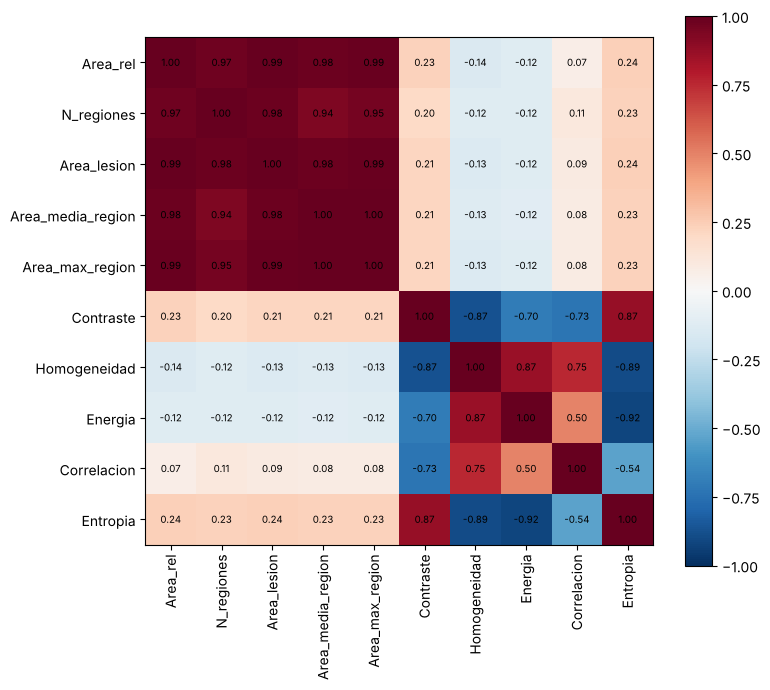

In [3]:
# Correlación entre características (Spearman), para elegir pocas y no redundantes
corr = datos[["Area_rel", "N_regiones", "Area_lesion", "Area_media_region", "Area_max_region"] + TEXT].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
plt.tight_layout()
plt.show()

&ensp; La entrada es `data/caracteristicas_cortes.csv` (notebook 04), solo con los cortes que pasaron el descarte de 4.2: 2762 cortes, de los cuales 2760 no tienen NaN (se pierden 2 cortes de MS sin textura). Quedan 1467 cortes de Control y 1293 de MS, así que las clases están casi balanceadas a nivel de corte.

**Elección de características.** Las cinco medidas de la segmentación están casi perfectamente correlacionadas entre sí (Spearman entre 0,94 y 1,00): miden lo mismo. Se conservan tres que aportan matices distintos: `Area_rel` (cuánto se marca, relativo al cerebro), `N_regiones` (cuántas manchas) y `Area_max_region` (tamaño de la mayor). Las de textura están bastante correlacionadas entre sí (|ρ| entre 0,50 y 0,92), pero poco con las de segmentación (|ρ| ≤ 0,24), así que aportan información distinta. Se usan las cinco. Se agrega `Eje_axial` (1 = axial, 0 = sagital) porque las distribuciones cambian con el eje.

**Limitación.** Con características tan correlacionadas, los coeficientes de la regresión logística no se pueden interpretar uno por uno (sección 5.6).

## 5.2 Grupos para la validación cruzada

In [4]:
# Grupos de "paciente" para que los cortes de un mismo sujeto no queden repartidos entre entrenamiento y prueba.
# - Control con ID: el ID real (compartido entre axial y sagital).
# - Control sin ID (149 axiales en dos series, "kontrol (n)" y "kontrol aks (n)"): bloques de BLOQUE_CONTROL
#   archivos consecutivos dentro de cada serie.
# - MS (sin ID): bloques de archivos consecutivos del contador n, de tamaño cortes / 72 pacientes en cada eje.
#   APROXIMACIÓN: no se sabe si el contador sigue el orden de los pacientes (la reconstrucción por saltos de
#   tamaño del notebook 01 se refutó en Control).
N_PACIENTES_MS = 72
BLOQUE_CONTROL = 14

def grupos_aproximados(df, n_pac_ms=N_PACIENTES_MS, bloque_control=BLOQUE_CONTROL, inventario=None):
    inv = df if inventario is None else inventario       # el tamaño de bloque se calcula sobre el inventario completo
    g = pd.Series(index=df.index, dtype=object)
    ctrl = df["Clase"] == "Control"
    con_id = ctrl & df["IdNombre"].notna()
    g[con_id] = "C" + df.loc[con_id, "IdNombre"].astype(int).astype(str)
    sin_id = ctrl & df["IdNombre"].isna()
    serie = df.loc[sin_id, "Ruta"].str.contains("aks").map({True: "aks", False: "k"})
    g[sin_id] = "C_" + serie + "_" + ((df.loc[sin_id, "Corte"] - 1) // bloque_control).astype(str)
    for eje in ["Axial", "Sagital"]:
        ms = (df["Clase"] == "MS") & (df["Eje"] == eje)
        n_total = ((inv["Clase"] == "MS") & (inv["Eje"] == eje)).sum()
        tam = round(n_total / n_pac_ms)
        g[ms] = f"MS_{eje[0]}_" + ((df.loc[ms, "Corte"] - 1) // tam).astype(str)
    return g

datos["Grupo"] = grupos_aproximados(datos, inventario=feat)
resumen = datos.groupby("Clase")["Grupo"].agg(["nunique", lambda s: s.value_counts().median()])
resumen.columns = ["Grupos", "Mediana de cortes por grupo"]
resumen

,Grupos,Mediana de cortes por grupo
Clase,,
Control,60,27.0
MS,142,9.0


&ensp; Si los cortes de un mismo paciente quedan repartidos entre entrenamiento y prueba, el modelo puede «reconocer» al paciente en vez de aprender a distinguir MS de Control, y el rendimiento sale inflado (**fuga de información**). Para evitarlo se arman grupos de paciente y se usa una partición que mantiene cada grupo entero en una sola partición (`StratifiedGroupKFold`). Los grupos son:

- **Control con ID** (48 sujetos): el ID real, que es el mismo en axial y sagital, así que cada grupo incluye los dos ejes.
- **Control sin ID** (149 axiales en dos series, `kontrol (n)` y `kontrol aks (n)`): bloques de 14 archivos consecutivos (149 cortes / 11 sujetos ≈ 14). Resultan 12 grupos.
- **MS** (sin ID): bloques de archivos consecutivos del contador, de 9 en axial (650 / 72) y 11 en sagital (761 / 72).

&ensp; Resultan 60 grupos de Control (mediana de 27 cortes por grupo) y 142 de MS (mediana de 9).

**Limitaciones **
- **Los grupos de MS son una aproximación**: no se sabe si el contador sigue el orden de los pacientes. En el notebook 01 se refutó la reconstrucción por saltos de tamaño, así que no hay forma de validar los bloques.
- En MS, el axial y el sagital de un mismo paciente quedan en grupos distintos, porque los contadores `A1` y `S1` son independientes. Pueden caer uno en entrenamiento y otro en prueba.
- Los grupos de Control y de MS no son comparables: los de Control juntan los dos ejes y tienen  27 cortes, y los de MS tienen 9.

## 5.3 Validación cruzada de los modelos

In [5]:
# Validación cruzada con 5 particiones. La estandarización va dentro del pipeline, así que se ajusta en cada
# partición solo con los datos de entrenamiento. Balanceo: class_weight="balanced" o submuestreo de la clase
# mayoritaria en el entrenamiento.
SEMILLA = 0
K = 5

MODELOS = {
    "Regresión logística": lambda cw: make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw, max_iter=1000)),
    "Random forest": lambda cw: make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight=cw, random_state=SEMILLA, n_jobs=1)),
}

def submuestrear(idx, y, rng):
    clases, cuentas = np.unique(y[idx], return_counts=True)
    n = cuentas.min()
    return np.concatenate([rng.choice(idx[y[idx] == c], n, replace=False) for c in clases])

def validar(modelo, X, y, grupos=None, balanceo="class_weight", k=K, semilla=SEMILLA):
    """Probabilidades fuera de la partición (out-of-fold) y AUC de cada partición."""
    if grupos is None:
        cv = StratifiedKFold(k, shuffle=True, random_state=semilla).split(X, y)
    else:
        cv = StratifiedGroupKFold(k, shuffle=True, random_state=semilla).split(X, y, grupos)
    rng = np.random.default_rng(semilla)
    proba, aucs = np.zeros(len(y)), []
    for tr, te in cv:
        if balanceo == "submuestreo":
            tr = submuestrear(tr, y, rng)
        m = modelo.fit(X[tr], y[tr])
        proba[te] = m.predict_proba(X[te])[:, 1]
        aucs.append(roc_auc_score(y[te], proba[te]))
    return proba, np.array(aucs)

def metricas(y, proba, umbral=0.5):
    tn, fp, fn, tp = confusion_matrix(y, proba >= umbral).ravel()
    return {"AUC": roc_auc_score(y, proba), "Sensibilidad": tp / (tp + fn), "Especificidad": tn / (tn + fp),
            "TP": tp, "FN": fn, "TN": tn, "FP": fp}

In [6]:
# Tres conjuntos de características, dos modelos, dos esquemas de partición y dos formas de balancear
CONJUNTOS = {"Segmentación": SEG + ["Eje_axial"], "Textura": TEXT + ["Eje_axial"],
             "Todas": SEG + TEXT + ["Eje_axial"]}
y = datos["y"].to_numpy()
grupos = datos["Grupo"].to_numpy()

filas, oof = [], {}
for conj, cols in CONJUNTOS.items():
    X = datos[cols].to_numpy()
    for nombre, hacer in MODELOS.items():
        for particion, g in [("Por corte", None), ("Por grupo", grupos)]:
            for balanceo in ["class_weight", "submuestreo"]:
                cw = "balanced" if balanceo == "class_weight" else None
                proba, aucs = validar(hacer(cw), X, y, g, balanceo)
                oof[(conj, nombre, particion, balanceo)] = proba
                filas.append({"Características": conj, "Modelo": nombre, "Partición": particion, "Balanceo": balanceo,
                              **metricas(y, proba), "AUC media por partición": aucs.mean(), "AUC desvío": aucs.std()})
res = pd.DataFrame(filas)
res[["Características", "Modelo", "Partición", "Balanceo", "AUC", "AUC media por partición", "AUC desvío",
     "Sensibilidad", "Especificidad"]].round(3)

,Características,Modelo,Partición,Balanceo,AUC,AUC media por partición,AUC desvío,Sensibilidad,Especificidad
0,Segmentación,Regresión logística,Por corte,class_weight,0.745,0.751,0.027,0.623,0.753
1,Segmentación,Regresión logística,Por corte,submuestreo,0.745,0.751,0.026,0.623,0.753
2,Segmentación,Regresión logística,Por grupo,class_weight,0.744,0.750,0.031,0.623,0.754
3,Segmentación,Regresión logística,Por grupo,submuestreo,0.743,0.750,0.032,0.622,0.753
4,Segmentación,Random forest,Por corte,class_weight,0.732,0.738,0.020,0.531,0.855
5,Segmentación,Random forest,Por corte,submuestreo,0.732,0.739,0.021,0.533,0.847
6,Segmentación,Random forest,Por grupo,class_weight,0.737,0.745,0.037,0.528,0.850
7,Segmentación,Random forest,Por grupo,submuestreo,0.735,0.744,0.036,0.540,0.847
8,Textura,Regresión logística,Por corte,class_weight,0.742,0.742,0.016,0.609,0.740
9,Textura,Regresión logística,Por corte,submuestreo,0.742,0.742,0.016,0.607,0.742


In [7]:
# Efecto de partir por grupo en vez de por corte (fuga entre cortes vecinos del mismo paciente)
piv = res.pivot_table(index=["Características", "Modelo", "Balanceo"], columns="Partición", values="AUC")
piv["Diferencia"] = piv["Por corte"] - piv["Por grupo"]
piv.round(3)

Partición                                         Por corte  Por grupo  \
Características Modelo              Balanceo                             
Segmentación    Random forest       class_weight      0.732      0.737   
                                    submuestreo       0.732      0.735   
                Regresión logística class_weight      0.745      0.744   
                                    submuestreo       0.745      0.743   
Textura         Random forest       class_weight      0.772      0.761   
                                    submuestreo       0.772      0.759   
                Regresión logística class_weight      0.742      0.740   
                                    submuestreo       0.742      0.740   
Todas           Random forest       class_weight      0.823      0.812   
                                    submuestreo       0.821      0.809   
                Regresión logística class_weight      0.811      0.809   
                                    submuestreo       0.811      0.809   

Partición                                         Diferencia  
Características Modelo              Balanceo                  
Segmentación    Random forest       class_weight      -0.005  
                                    submuestreo       -0.003  
                Regresión logística class_weight       0.001  
                                    submuestreo        0.002  
Textura         Random forest       class_weight       0.012  
                                    submuestreo        0.014  
                Regresión logística class_weight       0.002  
                                    submuestreo        0.002  
Todas           Random forest       class_weight       0.011  
                                    submuestreo        0.011  
                Regresión logística class_weight       0.002  
                                    submuestreo        0.002

&ensp; Se evaluaron 24 combinaciones: tres conjuntos de características (segmentación, textura y todas), dos modelos (regresión logística y random forest con 300 árboles y hojas de al menos 5 cortes), dos particiones (por corte y por grupo) y dos formas de balancear (`class_weight="balanced"` y submuestreo de la clase mayoritaria en el entrenamiento). Todas usan validación cruzada estratificada de 5 particiones, con semilla 0. La estandarización está dentro del pipeline, así que se ajusta en cada partición solo con los datos de entrenamiento.

| Características | Modelo | AUC por corte | AUC por grupo | Sens. (grupo) | Esp. (grupo) |
|---|---|---|---|---|---|
| Segmentación | Logística | 0,745 | 0,744 | 0,623 | 0,754 |
| Segmentación | Random forest | 0,732 | 0,737 | 0,528 | 0,850 |
| Textura | Logística | 0,742 | 0,740 | 0,616 | 0,735 |
| Textura | Random forest | 0,772 | 0,761 | 0,637 | 0,761 |
| Todas | Logística | 0,811 | 0,809 | 0,695 | 0,786 |
| Todas | Random forest | 0,823 | 0,812 | 0,663 | 0,829 |

*(con `class_weight="balanced"`; sensibilidad y especificidad con umbral 0,5)*

**Resultados.**
- **Combinar segmentación y textura** mejora claramente sobre cada conjunto por separado: el AUC por grupo pasa de 0,74–0,76 a 0,81. Es coherente con que los dos conjuntos están poco correlacionados.
- **Los dos modelos rinden parecido** con todas las características (0,809 contra 0,812 por grupo). El random forest no aporta una ventaja clara sobre un modelo lineal.
- **El balanceo no cambia el resultado** (diferencias ≤ 0,003 en AUC), porque las clases ya están casi balanceadas.
- **Partir por grupo casi no baja el AUC**: la diferencia es como mucho de 0,014, y en la logística no llega a 0,003. El que más baja es el random forest con textura o con todas las características (0,011–0,014), lo que tiene sentido porque es el modelo más flexible y el que más puede aprovechar la fuga. Esto sugiere que, con pocas características globales, la fuga entre cortes del mismo paciente es chica. Pero no lo demuestra: si los grupos de MS no corresponden a pacientes reales, la partición por grupo no está corrigiendo nada en MS.
- El desvío del AUC entre particiones es mayor por grupo (0,031–0,049) que por corte (0,010–0,027), como se espera al dejar grupos enteros afuera.

## 5.4 Modelo elegido: matriz de confusión y curva ROC

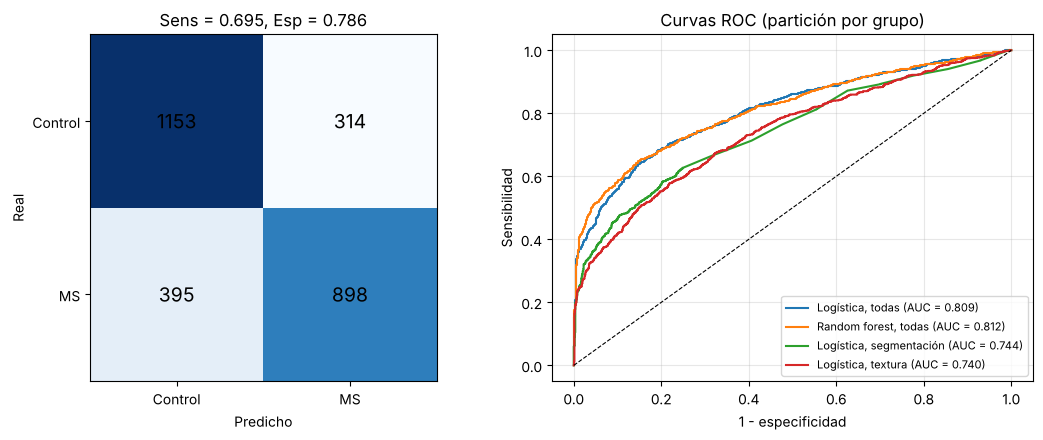

,AUC,Sensibilidad,Especificidad,TP,FN,TN,FP
Axial,0.857,0.728,0.856,425.0,159.0,596.0,100.0
Sagital,0.753,0.667,0.722,473.0,236.0,557.0,214.0


In [8]:
# Regresión logística con todas las características, partición por grupo y class_weight="balanced"
ELEGIDO = ("Todas", "Regresión logística", "Por grupo", "class_weight")
p_el = oof[ELEGIDO]
m_el = metricas(y, p_el)
cm = confusion_matrix(y, p_el >= 0.5)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axs[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
axs[0].set_xticks([0, 1], ["Control", "MS"]); axs[0].set_yticks([0, 1], ["Control", "MS"])
axs[0].set_xlabel("Predicho"); axs[0].set_ylabel("Real")
axs[0].set_title(f"Sens = {m_el['Sensibilidad']:.3f}, Esp = {m_el['Especificidad']:.3f}")
for clave, etiqueta in [(ELEGIDO, "Logística, todas"), (("Todas", "Random forest", "Por grupo", "class_weight"), "Random forest, todas"),
                        (("Segmentación", "Regresión logística", "Por grupo", "class_weight"), "Logística, segmentación"),
                        (("Textura", "Regresión logística", "Por grupo", "class_weight"), "Logística, textura")]:
    fpr, tpr, _ = roc_curve(y, oof[clave])
    axs[1].plot(fpr, tpr, label=f"{etiqueta} (AUC = {roc_auc_score(y, oof[clave]):.3f})")
axs[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axs[1].set_xlabel("1 - especificidad"); axs[1].set_ylabel("Sensibilidad")
axs[1].set_title("Curvas ROC (partición por grupo)")
axs[1].legend(fontsize=8)
axs[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Rendimiento por eje
pd.DataFrame({eje: metricas(y[datos["Eje"] == eje], p_el[datos["Eje"] == eje]) for eje in ["Axial", "Sagital"]}).T.round(3)

&ensp; Se eligió la **regresión logística con todas las características**, partición por grupo y `class_weight="balanced"`. Rinde casi igual que el random forest (AUC 0,809 contra 0,812), es más simple y sus coeficientes se pueden revisar.

- **Global:** AUC = 0,809, sensibilidad = 0,695 y especificidad = 0,786 con umbral 0,5.
- **Por eje:** funciona bastante mejor en **axial** (AUC 0,857, sensibilidad 0,728, especificidad 0,856) que en **sagital** (AUC 0,753, sensibilidad 0,667, especificidad 0,722). Coincide con lo visto en 4.4, donde las diferencias entre clases eran mayores en axial.

**Limitaciones.** El umbral de 0,5 no se optimizó; moverlo cambia el equilibrio entre sensibilidad y especificidad. A nivel de corte, el clasificador se equivoca en aproximadamente 1 de cada 4 cortes, lo cual es esperable porque muchos cortes de MS no tienen lesiones visibles.

## 5.5 Clasificación por paciente aproximado

In [9]:
# Se promedian las probabilidades fuera de la partición de los cortes de cada grupo y se clasifica el grupo
def por_grupo(proba, df=datos):
    agg = pd.DataFrame({"Grupo": df["Grupo"], "y": df["y"], "p": proba}).groupby("Grupo").agg(y=("y", "first"), p=("p", "mean"))
    return agg

filas = []
for clave in [k for k in oof if k[2] == "Por grupo" and k[3] == "class_weight"]:
    agg = por_grupo(oof[clave])
    filas.append({"Características": clave[0], "Modelo": clave[1], "Nivel": "Grupo", "n": len(agg),
                  **metricas(agg["y"].to_numpy(), agg["p"].to_numpy())})
    filas.append({"Características": clave[0], "Modelo": clave[1], "Nivel": "Corte", "n": len(y),
                  **metricas(y, oof[clave])})
niveles = pd.DataFrame(filas)
niveles.pivot_table(index=["Características", "Modelo"], columns="Nivel", values=["AUC", "Sensibilidad", "Especificidad"]).round(3)

AUC        Especificidad         \
Nivel                                Corte  Grupo         Corte  Grupo   
Características Modelo                                                   
Segmentación    Random forest        0.737  0.930         0.850  0.967   
                Regresión logística  0.744  0.936         0.754  0.983   
Textura         Random forest        0.761  0.901         0.761  0.950   
                Regresión logística  0.740  0.852         0.735  0.833   
Todas           Random forest        0.812  0.935         0.829  0.967   
                Regresión logística  0.809  0.921         0.786  0.933   

                                    Sensibilidad         
Nivel                                      Corte  Grupo  
Características Modelo                                   
Segmentación    Random forest              0.528  0.754  
                Regresión logística        0.623  0.768  
Textura         Random forest              0.637  0.718  
                Regresión logística        0.616  0.711  
Todas           Random forest              0.663  0.775  
                Regresión logística        0.695  0.775

&ensp; En la práctica el diagnóstico es por paciente, no por corte. Para cada grupo se promedia la probabilidad de MS de sus cortes (las de la validación por grupo, es decir, de cortes que el modelo no vio al entrenar) y se clasifica el grupo con umbral 0,5. Resultan 202 grupos: 60 de Control y 142 de MS.

| Características | Modelo | AUC corte | AUC grupo | Sens. grupo | Esp. grupo |
|---|---|---|---|---|---|
| Segmentación | Logística | 0,744 | 0,936 | 0,768 | 0,983 |
| Textura | Logística | 0,740 | 0,852 | 0,711 | 0,833 |
| Todas | Logística | 0,809 | 0,921 | 0,775 | 0,933 |
| Todas | Random forest | 0,812 | 0,935 | 0,775 | 0,967 |

&ensp; Al agregar por grupo, el AUC sube de ~0,74–0,81 a ~0,85–0,94: promediar varios cortes reduce el ruido de cada corte individual.

**Limitaciones **
- **Los grupos de MS no son pacientes reales** (5.2), así que este no es el rendimiento por paciente: es el rendimiento por bloque de archivos consecutivos.
- **Los grupos de Control promedian unos 27 cortes y los de MS unos 9.** Promediar más cortes da probabilidades más estables, lo que favorece la especificidad: en todos los modelos supera a la sensibilidad (0,83–0,98 contra 0,71–0,78). La asimetría puede deberse en parte a esto y no al método.
- El n es chico (60 grupos de Control), así que la especificidad por grupo tiene mucha incertidumbre: cada grupo mal clasificado son 1,7 puntos porcentuales.

## 5.6 Importancia de las características

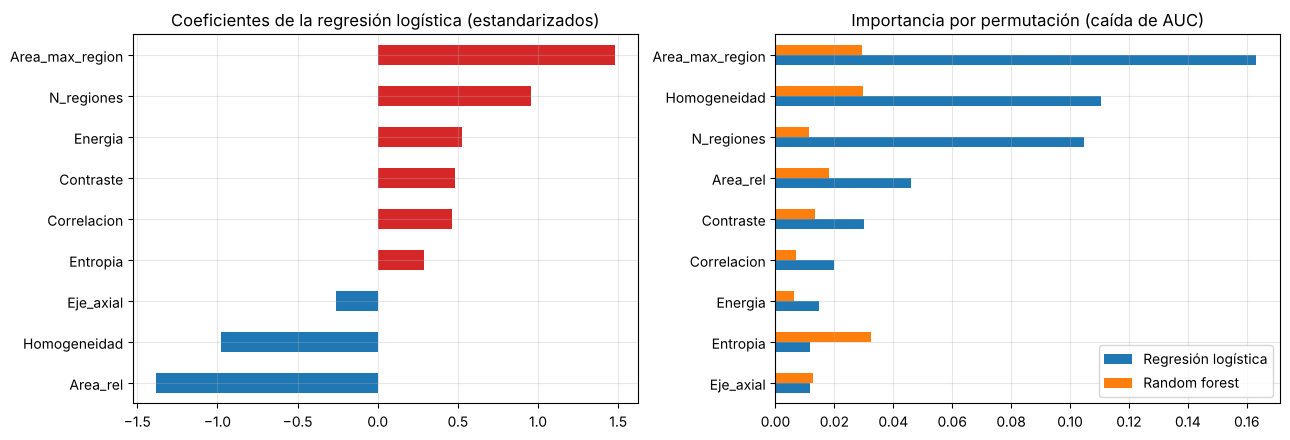

,Coef. logística,Regresión logística,Random forest
Area_rel,-1.384,0.046,0.018
Homogeneidad,-0.977,0.111,0.030
Eje_axial,-0.260,0.012,0.013
Entropia,0.291,0.012,0.032
Correlacion,0.465,0.020,0.007
Contraste,0.479,0.030,0.013
Energia,0.524,0.015,0.006
N_regiones,0.956,0.105,0.011
Area_max_region,1.477,0.163,0.029


In [10]:
# Coeficientes de la regresión logística ajustada con todos los datos (características estandarizadas):
# positivo = empuja hacia MS
cols = CONJUNTOS["Todas"]
log = MODELOS["Regresión logística"]("balanced").fit(datos[cols].to_numpy(), y)
coef = pd.Series(log[-1].coef_[0], index=cols).sort_values()

# Importancia por permutación sobre las particiones de prueba (partición por grupo): caída media de AUC
imp = {n: [] for n in MODELOS}
cv = list(StratifiedGroupKFold(K, shuffle=True, random_state=SEMILLA).split(datos[cols], y, grupos))
X = datos[cols].to_numpy()
for nombre, hacer in MODELOS.items():
    for tr, te in cv:
        m = hacer("balanced").fit(X[tr], y[tr])
        r = permutation_importance(m, X[te], y[te], scoring="roc_auc", n_repeats=10, random_state=SEMILLA)
        imp[nombre].append(r.importances_mean)
imp = pd.DataFrame({n: np.mean(v, axis=0) for n, v in imp.items()}, index=cols)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
coef.plot.barh(ax=axs[0], color=np.where(coef > 0, "tab:red", "tab:blue"))
axs[0].set_title("Coeficientes de la regresión logística (estandarizados)")
axs[0].grid(True, alpha=0.3)
imp.sort_values("Regresión logística").plot.barh(ax=axs[1])
axs[1].set_title("Importancia por permutación (caída de AUC)")
axs[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
pd.concat([coef.rename("Coef. logística"), imp], axis=1).round(3)

&ensp; Se calcularon dos medidas de importancia. Los **coeficientes** de la regresión logística, ajustada con todos los datos y con las características estandarizadas, indican hacia qué clase empuja cada una (positivo = MS). La **importancia por permutación** se calculó sobre las particiones de prueba de la validación por grupo: es la caída media de AUC al desordenar cada característica.

| Característica | Coef. logística | Permutación (logística) | Permutación (random forest) |
|---|---|---|---|
| Area_max_region | 1,477 | 0,163 | 0,029 |
| Homogeneidad | −0,977 | 0,111 | 0,030 |
| N_regiones | 0,956 | 0,105 | 0,011 |
| Area_rel | −1,384 | 0,046 | 0,018 |
| Entropía | 0,291 | 0,012 | 0,032 |
| Contraste | 0,479 | 0,030 | 0,013 |

**Interpretación.**
- En la logística, lo que más pesa es **la segmentación** (`Area_max_region` y `N_regiones`) junto con la **homogeneidad** de la sustancia blanca. En el random forest la importancia está más repartida: entropía, homogeneidad y `Area_max_region` quedan parejas (≈ 0,03).
- En ambos modelos aparecen características de los dos conjuntos entre las más importantes, lo que es coherente con que combinarlas mejore el AUC (5.3).
- **Los signos individuales no se pueden interpretar**: `Area_rel` tiene coeficiente negativo y `Area_max_region` positivo, aunque las dos son mayores en MS (4.4) y su correlación es 0,99. Con características tan correlacionadas, el modelo reparte el peso entre ellas de forma arbitraria. Lo que importa es el conjunto, no cada coeficiente. Lo mismo pasa entre homogeneidad y energía.
- `Eje_axial` tiene poca importancia por sí sola, pero el rendimiento es distinto en cada eje (5.4).